# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [5]:
#Load cleaned data
data = pd.read_csv(
    "C:/Users/SHIRLENE OUMA/AviationData_Cleaned.csv",
    encoding="utf-8",
    low_memory=False
)

In [6]:
data.head()

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.Occupants,Fatal.Serious.Injuries,Injury.Rate,Aircraft.Destroyed,Aircraft.Type
0,20001214X42478,Incident,LAX83IA149A,1983-03-18,"LOS ANGELES, CA",United States,NaN,NaN,LAX,LOS ANGELES INTL,...,588.0,vmc,taxi,Probable Cause,04-12-2014,588.0,NaN,NaN,0.0,BOEING - 747
1,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,NaN,NaN,NaN,NaN,...,NaN,imc,cruise,Probable Cause,02-05-2011,2.0,2.0,1.0,1.0,PIPER - PA-28-140
2,20001214X42672,Accident,FTW83LA177,1983-04-02,"MCKINNEY, TX",United States,NaN,NaN,TX05,AERO COUNTRY,...,4.0,vmc,standing,Probable Cause,17-10-2016,5.0,NaN,NaN,NaN,DE HAVILLAND - DHC-6
3,20001214X45013,Incident,CHI84IA041,1983-11-08,"CHICAGO, IL",United States,NaN,NaN,ORD,O'HARE,...,100.0,vmc,taxi,Probable Cause,11-06-2018,100.0,NaN,NaN,0.0,BOEING - 727-200
4,20001214X45188,Accident,NYC84LA028,1983-11-13,"MARTHA'S VINEYARD, MA",United States,NaN,NaN,NaN,NaN,...,1.0,vmc,climb,Probable Cause,05-05-2011,1.0,NaN,NaN,0.0,BEECH - C35


In [7]:
print(data.columns.tolist())
print(data.shape)

['Event.Id', 'Investigation.Type', 'Accident.Number', 'Event.Date', 'Location', 'Country', 'Latitude', 'Longitude', 'Airport.Code', 'Airport.Name', 'Injury.Severity', 'Aircraft.damage', 'Aircraft.Category', 'Registration.Number', 'Make', 'Model', 'Amateur.Built', 'Number.of.Engines', 'Engine.Type', 'FAR.Description', 'Purpose.of.flight', 'Air.carrier', 'Total.Fatal.Injuries', 'Total.Serious.Injuries', 'Total.Minor.Injuries', 'Total.Uninjured', 'Weather.Condition', 'Broad.phase.of.flight', 'Report.Status', 'Publication.Date', 'Total.Occupants', 'Fatal.Serious.Injuries', 'Injury.Rate', 'Aircraft.Destroyed', 'Aircraft.Type']
(17879, 35)


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [8]:
# Convert relevant columns to numeric
for col in ["Total.Fatal.Injuries", "Total.Serious.Injuries",
            "Total.Occupants", "Aircraft.Destroyed"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")


In [9]:
# Calculate the fraction of occupants seriously or fatally injured
data["Serious.Fatal.Fraction"] = (
    data["Total.Fatal.Injuries"] + data["Total.Serious.Injuries"]
) / data["Total.Occupants"]

In [10]:
# Remove impossible fractions and invalid occupant counts
data.loc[
    (data["Total.Occupants"] <= 0) |
    (data["Serious.Fatal.Fraction"] < 0) |
    (data["Serious.Fatal.Fraction"] > 1),
    "Serious.Fatal.Fraction"
] = np.nan

In [11]:
# Separate small and large aircraft
data["Aircraft.Size"] = np.where(
    data["Total.Occupants"] >= 20,
    "Large",
    "Small"
)

In [12]:
# Unknown occupant counts should not be classified
data.loc[data["Total.Occupants"].isna(), "Aircraft.Size"] = np.nan

data["Aircraft.Size"].value_counts(dropna=False)

Small    16965
Large      878
NaN         36
Name: Aircraft.Size, dtype: int64

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [13]:
make_stats = (
    data.groupby(["Aircraft.Size", "Make"])
    .agg(
        accidents=("Make", "size"),
        injury_samples=("Serious.Fatal.Fraction", "count"),
        mean_injury_rate=("Serious.Fatal.Fraction", "mean"),
        destruction_samples=("Aircraft.Destroyed", "count"),
        destruction_rate=("Aircraft.Destroyed", "mean")
    )
    .reset_index()
)

In [14]:
# Minimum 10 valid observations for each metric
eligible_injury_makes = make_stats[
    make_stats["injury_samples"] >= 10
]

eligible_damage_makes = make_stats[
    make_stats["destruction_samples"] >= 10
]

make_stats.head()

,Aircraft.Size,Make,accidents,injury_samples,mean_injury_rate,destruction_samples,destruction_rate
0,Large,AIRBUS,118,114,0.080503,53,0.169811
1,Large,BEECH,2,2,1.000000,2,1.000000
2,Large,BOEING,547,489,0.057161,282,0.095745
3,Large,BOMBARDIER,21,19,0.070406,18,0.055556
4,Large,BOMBARDIER INC,44,44,0.028038,27,0.037037


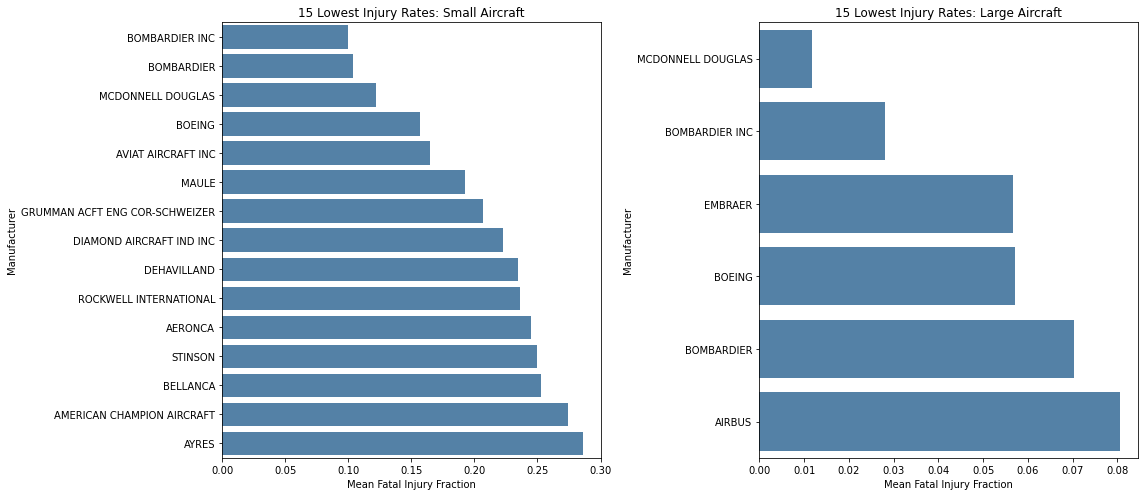

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, size in zip(axes, ["Small", "Large"]):
    top15 = (
        eligible_injury_makes[
            eligible_injury_makes["Aircraft.Size"] == size
        ]
        .nsmallest(15, "mean_injury_rate")
    )

    sns.barplot(
        data=top15,
        x="mean_injury_rate",
        y="Make",
        ax=ax,
        color="steelblue"
    )

    ax.set_title(f"15 Lowest Injury Rates: {size} Aircraft")
    ax.set_xlabel("Mean Fatal Injury Fraction")
    ax.set_ylabel("Manufacturer")

plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

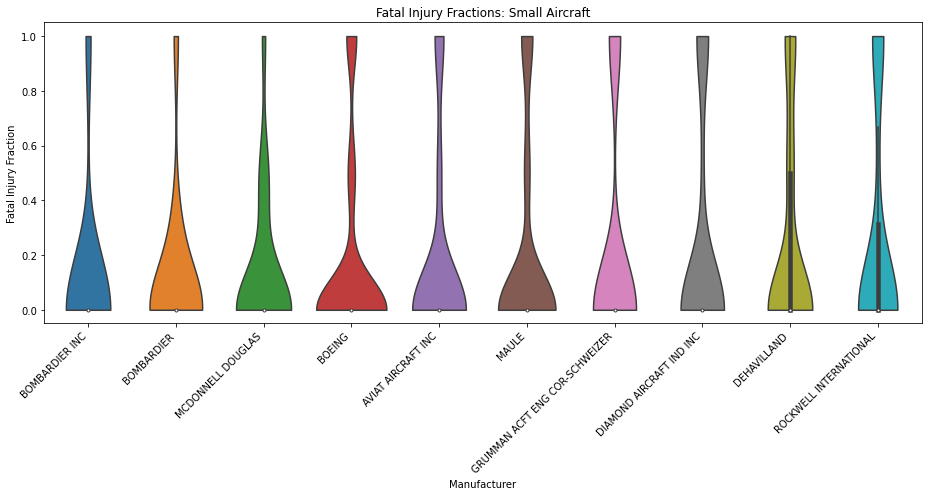

In [21]:
small_top10 = (
    eligible_injury_makes[
        eligible_injury_makes["Aircraft.Size"] == "Small"
    ]
    .nsmallest(10, "mean_injury_rate")["Make"]
)

small_data = data[
    (data["Aircraft.Size"] == "Small") &
    (data["Make"].isin(small_top10))
]

plt.figure(figsize=(13, 7))

sns.violinplot(
    data=small_data,
    x="Make",
    y="Serious.Fatal.Fraction",
    order=small_top10.tolist(),
    cut=0
)

plt.xticks(rotation=45, ha="right")
plt.title("Fatal Injury Fractions: Small Aircraft")
plt.ylabel("Fatal Injury Fraction")
plt.xlabel("Manufacturer")
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

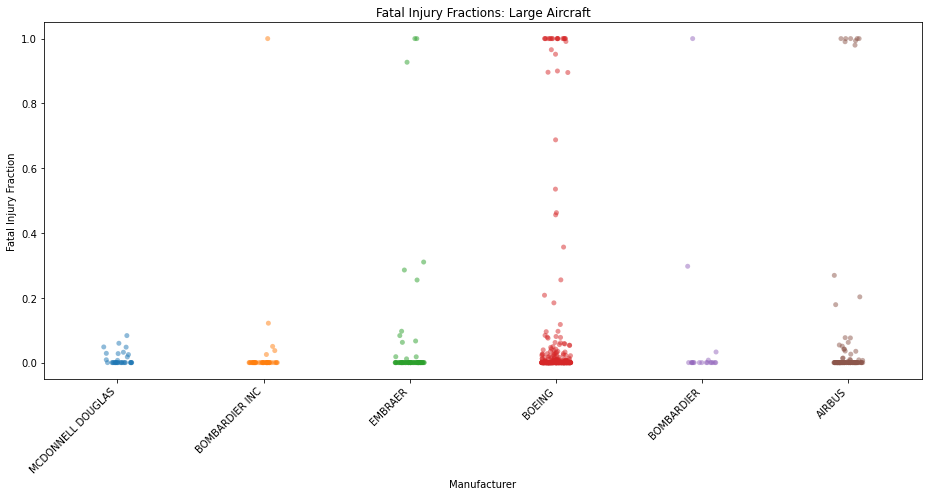

In [22]:
large_top10 = (
    eligible_injury_makes[
        eligible_injury_makes["Aircraft.Size"] == "Large"
    ]
    .nsmallest(10, "mean_injury_rate")["Make"]
)

large_data = data[
    (data["Aircraft.Size"] == "Large") &
    (data["Make"].isin(large_top10))
]

plt.figure(figsize=(13, 7))

sns.stripplot(
    data=large_data,
    x="Make",
    y="Serious.Fatal.Fraction",
    order=large_top10.tolist(),
    jitter=True,
    alpha=0.5
)

plt.xticks(rotation=45, ha="right")
plt.title("Fatal Injury Fractions: Large Aircraft")
plt.ylabel("Fatal Injury Fraction")
plt.xlabel("Manufacturer")
plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

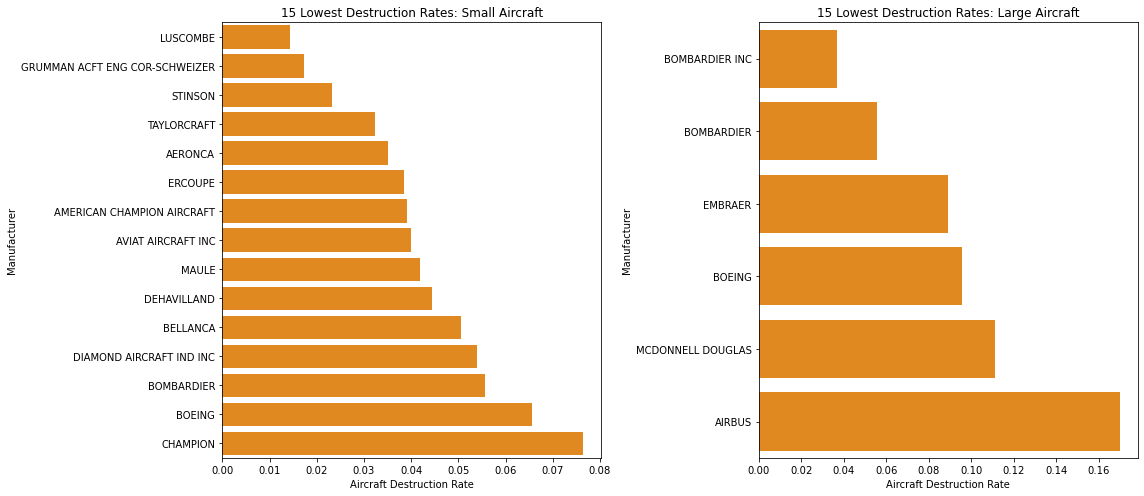

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, size in zip(axes, ["Small", "Large"]):
    top15 = (
        eligible_damage_makes[
            eligible_damage_makes["Aircraft.Size"] == size
        ]
        .nsmallest(15, "destruction_rate")
    )

    sns.barplot(
        data=top15,
        x="destruction_rate",
        y="Make",
        ax=ax,
        color="darkorange"
    )

    ax.set_title(f"15 Lowest Destruction Rates: {size} Aircraft")
    ax.set_xlabel("Aircraft Destruction Rate")
    ax.set_ylabel("Manufacturer")

plt.tight_layout()
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

In [30]:
# Identify manufacturers with sufficient observations
recommended_makes = make_stats[
    (make_stats["injury_samples"] >= 10) &
    (make_stats["destruction_samples"] >= 10)
].copy()

In [31]:
# Rank both safety measures within each size group
recommended_makes["Injury.Rank"] = (
    recommended_makes.groupby("Aircraft.Size")["mean_injury_rate"]
    .rank(method="min")
)

recommended_makes["Destruction.Rank"] = (
    recommended_makes.groupby("Aircraft.Size")["destruction_rate"]
    .rank(method="min")
)

recommended_makes["Combined.Rank"] = (
    recommended_makes["Injury.Rank"] +
    recommended_makes["Destruction.Rank"]
)

for size in ["Small", "Large"]:
    print("\n", size, "AIRCRAFT MANUFACTURERS")

    display(
        recommended_makes[
            recommended_makes["Aircraft.Size"] == size
        ]
        .sort_values("Combined.Rank")
        .head(10)
    )


 Small AIRCRAFT MANUFACTURERS


,Aircraft.Size,Make,accidents,injury_samples,mean_injury_rate,destruction_samples,destruction_rate,Injury.Rank,Destruction.Rank,Combined.Rank
37,Small,GRUMMAN ACFT ENG COR-SCHWEIZER,58,58,0.206897,58,0.017241,7.0,2.0,9.0
20,Small,AVIAT AIRCRAFT INC,76,76,0.164474,75,0.040000,5.0,8.0,13.0
39,Small,MAULE,215,171,0.192593,215,0.041860,6.0,9.0,15.0
47,Small,STINSON,129,112,0.249256,129,0.023256,12.0,3.0,15.0
25,Small,BOMBARDIER,29,15,0.103846,18,0.055556,2.0,13.0,15.0
14,Small,AERONCA,200,168,0.245040,200,0.035000,11.0,5.0,16.0
24,Small,BOEING,694,232,0.156968,381,0.065617,4.0,14.0,18.0
32,Small,DEHAVILLAND,93,92,0.234170,90,0.044444,9.0,10.0,19.0
26,Small,BOMBARDIER INC,21,10,0.100000,10,0.100000,1.0,18.0,19.0
33,Small,DIAMOND AIRCRAFT IND INC,74,74,0.222973,74,0.054054,8.0,12.0,20.0



 Large AIRCRAFT MANUFACTURERS


,Aircraft.Size,Make,accidents,injury_samples,mean_injury_rate,destruction_samples,destruction_rate,Injury.Rank,Destruction.Rank,Combined.Rank
4,Large,BOMBARDIER INC,44,44,0.028038,27,0.037037,2.0,1.0,3.0
8,Large,EMBRAER,78,73,0.056642,45,0.088889,3.0,3.0,6.0
10,Large,MCDONNELL DOUGLAS,53,33,0.011661,36,0.111111,1.0,5.0,6.0
3,Large,BOMBARDIER,21,19,0.070406,18,0.055556,5.0,2.0,7.0
2,Large,BOEING,547,489,0.057161,282,0.095745,4.0,4.0,8.0
0,Large,AIRBUS,118,114,0.080503,53,0.169811,6.0,6.0,12.0


### Discussion of Aircraft Manufacturers

The analysis compared aircraft manufacturers based on two important safety measures: the mean fraction of occupants who sustained serious or fatal injuries and the proportion of recorded accidents resulting in complete aircraft destruction.

Small and large aircraft were analyzed separately using a threshold of 20 occupants. Manufacturers with fewer than 10 valid accident observations were excluded from the comparisons to reduce the influence of very small samples.

The bar charts identify manufacturers with lower average injury severity and destruction rates, while the violin and strip plots illustrate how injury severity varies across individual accidents.

Manufacturers with low values for both safety measures are stronger candidates for further consideration than manufacturers performing well on only one measure.

The distribution plots are particularly important because a low average injury fraction can hide a small number of very severe accidents.

**Recommendation:** Prioritize manufacturers that demonstrate consistently low serious/fatal injury fractions and aircraft destruction rates, supported by adequate sample sizes. Final selections should also consider aircraft age, operational use, and whether the model remains commercially active.

These findings describe the severity of recorded accidents, rather than the overall probability of an accident occurring.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

In [32]:
# Select large aircraft with at least 10 valid injury observations
large_types = (
    data[data["Aircraft.Size"] == "Large"]
    .groupby("Aircraft.Type")
    .agg(
        Sample_Size=("Serious.Fatal.Fraction", "count"),
        Mean_Injury_Fraction=("Serious.Fatal.Fraction", "mean")
    )
    .reset_index()
)

large_types = (
    large_types[large_types["Sample_Size"] >= 10]
    .sort_values("Mean_Injury_Fraction")
)

# Display the 15 lowest injury fractions
large_top15 = large_types.head(15)

display(large_top15)

,Aircraft.Type,Sample_Size,Mean_Injury_Fraction
149,BOEING - 777,31,0.000589
114,BOEING - 757,17,0.001560
165,BOEING - 787,11,0.003058
87,BOEING - 737-7H4,11,0.003537
206,BOMBARDIER INC - CL-600-2B19,15,0.004136
247,EMBRAER - EMB145,11,0.008798
242,EMBRAER - EMB-145LR,14,0.010714
102,BOEING - 747,10,0.025478
128,BOEING - 767,29,0.050201
65,BOEING - 737 7H4,14,0.068121


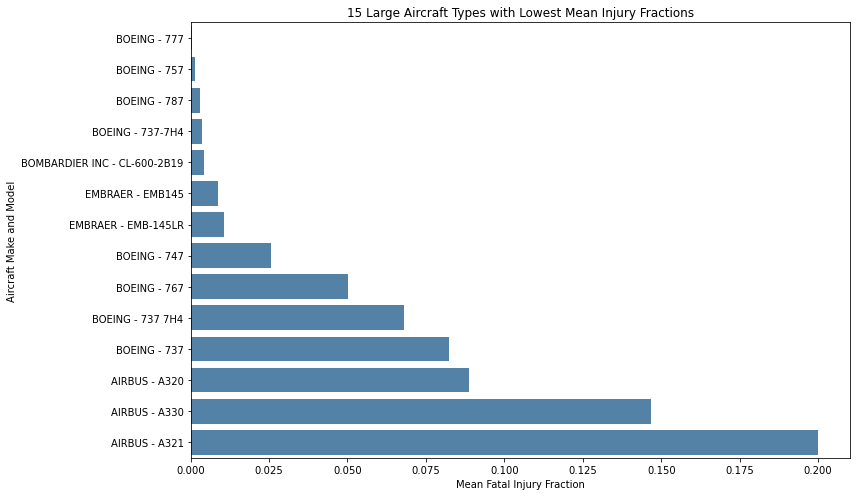

In [45]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=large_top15,
    x="Mean_Injury_Fraction",
    y="Aircraft.Type",
    color="steelblue"
)

plt.title("15 Large Aircraft Types with Lowest Mean Injury Fractions")
plt.xlabel("Mean Fatal Injury Fraction")
plt.ylabel("Aircraft Make and Model")

plt.tight_layout()
plt.show()

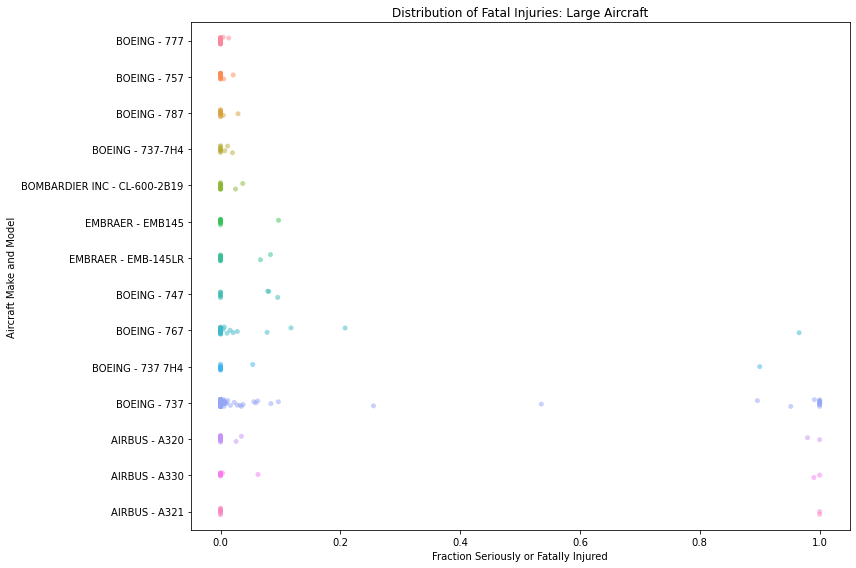

In [44]:
# Select individual accident records for the top 15 models
large_distribution = data[
    (data["Aircraft.Size"] == "Large") &
    (data["Aircraft.Type"].isin(large_top15["Aircraft.Type"]))
]

plt.figure(figsize=(12, 8))

sns.stripplot(
    data=large_distribution,
    x="Serious.Fatal.Fraction",
    y="Aircraft.Type",
    order=large_top15["Aircraft.Type"].tolist(),
    jitter=True,
    alpha=0.5
)

plt.title("Distribution of Fatal Injuries: Large Aircraft")
plt.xlabel("Fraction Seriously or Fatally Injured")
plt.ylabel("Aircraft Make and Model")

plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

In [35]:
# Find the 10 small-aircraft makes with lowest mean injury fractions
small_make_stats = (
    data[data["Aircraft.Size"] == "Small"]
    .groupby("Make")["Serious.Fatal.Fraction"]
    .agg(["mean", "count"])
    .reset_index()
)

small_make_stats = small_make_stats[
    small_make_stats["count"] >= 10
]

top10_small_makes = (
    small_make_stats
    .sort_values("mean")
    .head(10)["Make"]
)

# Filter to those makes
small_filtered = data[
    (data["Aircraft.Size"] == "Small") &
    (data["Make"].isin(top10_small_makes))
]

# Analyze individual models
small_types = (
    small_filtered
    .groupby("Aircraft.Type")
    .agg(
        Sample_Size=("Serious.Fatal.Fraction", "count"),
        Mean_Injury_Fraction=("Serious.Fatal.Fraction", "mean")
    )
    .reset_index()
)

small_types = (
    small_types[small_types["Sample_Size"] >= 10]
    .sort_values("Mean_Injury_Fraction")
)

small_top15 = small_types.head(15)

display(small_top15)

,Aircraft.Type,Sample_Size,Mean_Injury_Fraction
252,DIAMOND AIRCRAFT IND INC - DA 20 C1,11,0.000000
67,BOEING - 747,25,0.080000
29,BOEING - 737,36,0.083333
335,MAULE - MX7,18,0.125000
297,MAULE - M-5-235C,11,0.136364
148,BOEING - A75N1(PT17),30,0.144444
5,AVIAT AIRCRAFT INC - A-1B,22,0.181818
7,AVIAT AIRCRAFT INC - A-1C-180,13,0.192308
362,MCDONNELL DOUGLAS - MD11,11,0.198052
271,GRUMMAN ACFT ENG COR-SCHWEIZER - G-164A,10,0.200000


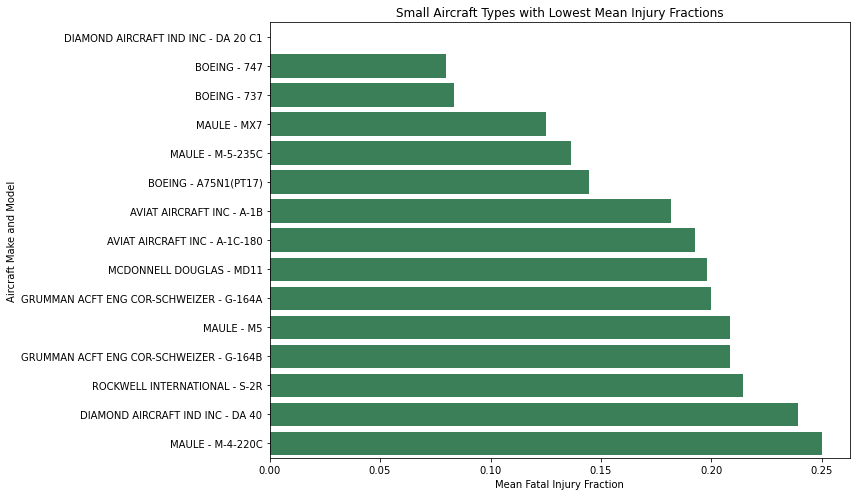

In [43]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=small_top15,
    x="Mean_Injury_Fraction",
    y="Aircraft.Type",
    color="seagreen"
)

plt.title("Small Aircraft Types with Lowest Mean Injury Fractions")
plt.xlabel("Mean Fatal Injury Fraction")
plt.ylabel("Aircraft Make and Model")

plt.tight_layout()
plt.show()

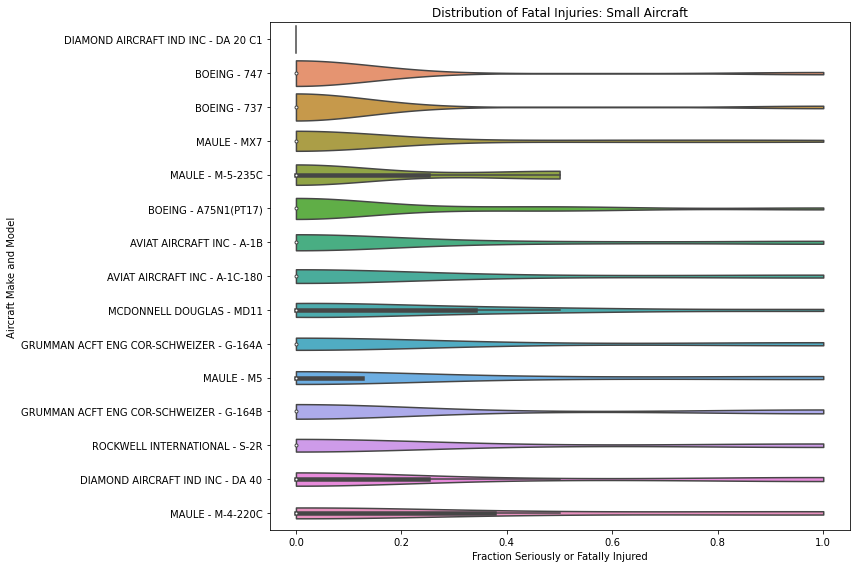

In [42]:
small_distribution = small_filtered[
    small_filtered["Aircraft.Type"].isin(small_top15["Aircraft.Type"])
]

plt.figure(figsize=(12, 8))

sns.violinplot(
    data=small_distribution,
    x="Serious.Fatal.Fraction",
    y="Aircraft.Type",
    order=small_top15["Aircraft.Type"].tolist(),
    cut=0
)

plt.title("Distribution of Fatal Injuries: Small Aircraft")
plt.xlabel("Fraction Seriously or Fatally Injured")
plt.ylabel("Aircraft Make and Model")

plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

In [38]:
# Compare both injury and destruction measures by aircraft type
model_safety = (
    data.groupby(["Aircraft.Size", "Aircraft.Type"])
    .agg(
        Injury_Samples=("Serious.Fatal.Fraction", "count"),
        Mean_Injury_Fraction=("Serious.Fatal.Fraction", "mean"),
        Damage_Samples=("Aircraft.Destroyed", "count"),
        Destruction_Rate=("Aircraft.Destroyed", "mean")
    )
    .reset_index()
)

model_safety = model_safety[
    (model_safety["Injury_Samples"] >= 10) &
    (model_safety["Damage_Samples"] >= 10)
]

display(
    model_safety.sort_values(
        ["Aircraft.Size", "Mean_Injury_Fraction", "Destruction_Rate"]
    )
)

,Aircraft.Size,Aircraft.Type,Injury_Samples,Mean_Injury_Fraction,Damage_Samples,Destruction_Rate
149,Large,BOEING - 777,31,0.000589,16,0.062500
206,Large,BOMBARDIER INC - CL-600-2B19,15,0.004136,11,0.000000
128,Large,BOEING - 767,29,0.050201,15,0.066667
50,Large,BOEING - 737,161,0.082232,98,0.112245
1485,Small,DIAMOND AIRCRAFT IND INC - DA 20 C1,11,0.000000,11,0.000000
...,...,...,...,...,...,...
1949,Small,PIPER - PA-23-250,17,0.632353,28,0.107143
630,Small,BEECH - B36TC,15,0.666667,20,0.350000
1209,Small,CESSNA - 421C,26,0.692308,30,0.266667
737,Small,BEECH - P35,11,0.742424,11,0.181818


### Discussion of Specific Aircraft Makes and Models

The analysis examined individual aircraft makes and models to identify differences in the severity of recorded aviation accidents.

For larger aircraft, the models were ranked according to their mean serious/fatal injury fraction. Only aircraft types with at least 10 valid observations were included, helping to reduce the influence of isolated accidents.

For smaller aircraft, the analysis first identified the 10 manufacturers with the lowest mean injury fractions before comparing individual models produced by those manufacturers.

The bar charts allow direct comparison of average injury severity, while the distribution plots show whether accident outcomes are relatively consistent or highly variable.

Aircraft models with low mean injury fractions and relatively few severe outcomes appear more favorable. However, a low mean does not guarantee that serious accidents cannot occur.

**Recommendation:** Consider the highest-performing small and large aircraft models separately, giving preference to those with low injury fractions, low destruction rates, and sufficient accident observations.

The results should be treated as preliminary evidence for insurance risk assessment, rather than definitive proof that one aircraft model is inherently safer than another.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

We will investigate two factors:
1. Weather Condition
2. Phase of Flight

### Factor 1: Weather Conditions

In [39]:
# Analyze accident outcomes by weather condition
weather_analysis = (
    data.groupby("Weather.Condition")
    .agg(
        Total_Accidents=("Weather.Condition", "size"),
        Injury_Samples=("Serious.Fatal.Fraction", "count"),
        Mean_Injury_Fraction=("Serious.Fatal.Fraction", "mean"),
        Damage_Samples=("Aircraft.Destroyed", "count"),
        Destruction_Rate=("Aircraft.Destroyed", "mean")
    )
    .reset_index()
)

In [40]:
# Keep groups with sufficient observations
weather_analysis = weather_analysis[
    (weather_analysis["Injury_Samples"] >= 10) &
    (weather_analysis["Damage_Samples"] >= 10)
]

display(weather_analysis)

,Weather.Condition,Total_Accidents,Injury_Samples,Mean_Injury_Fraction,Damage_Samples,Destruction_Rate
0,imc,905,776,0.650964,857,0.367561
1,unk,262,169,0.497642,202,0.341584
2,vmc,14295,11906,0.264223,14016,0.072275


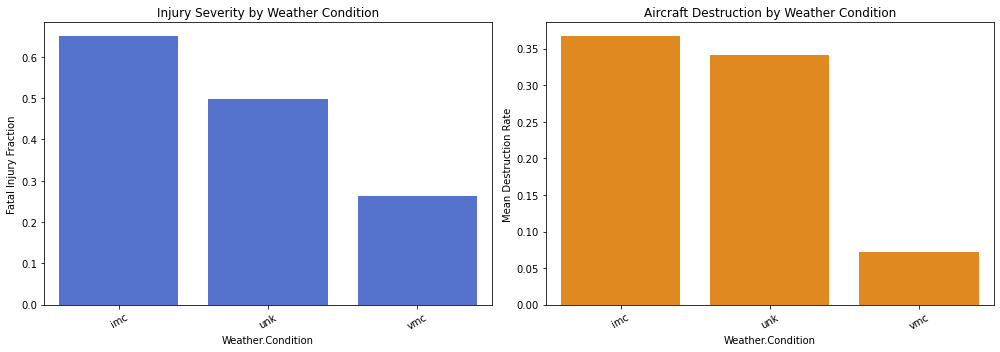

In [46]:
# Visualize both outcomes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=weather_analysis,
    x="Weather.Condition",
    y="Mean_Injury_Fraction",
    color="royalblue",
    ax=axes[0]
)

axes[0].set_title("Injury Severity by Weather Condition")
axes[0].set_ylabel("Fatal Injury Fraction")
axes[0].tick_params(axis="x", rotation=30)

sns.barplot(
    data=weather_analysis,
    x="Weather.Condition",
    y="Destruction_Rate",
    color="darkorange",
    ax=axes[1]
)

axes[1].set_title("Aircraft Destruction by Weather Condition")
axes[1].set_ylabel("Mean Destruction Rate")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

### Factor 1: Weather Condition

Weather conditions were investigated to determine whether accident severity varies across different flying conditions.

The analysis compared the mean fatal injury fraction and aircraft destruction rate across the recorded weather categories.

The summary statistics and bar charts provide a basis for identifying which conditions are associated with more severe accident outcomes.

Where a weather category has a higher mean injury fraction or destruction rate, this indicates that accidents recorded under that condition tended to have more severe consequences in the analyzed sample.

However, differences between weather categories do not necessarily establish that weather directly caused the observed outcomes. Other factors, including aircraft type, flight operations, and accident circumstances, may also influence severity.

The findings can help insurers identify weather-related risk patterns that warrant further investigation.

### Factor 2: Phase of flight

In [47]:
# Analyze accident outcomes by phase of flight
phase_analysis = (
    data.groupby("Broad.phase.of.flight")
    .agg(
        Total_Accidents=("Broad.phase.of.flight", "size"),
        Injury_Samples=("Serious.Fatal.Fraction", "count"),
        Mean_Injury_Fraction=("Serious.Fatal.Fraction", "mean"),
        Damage_Samples=("Aircraft.Destroyed", "count"),
        Destruction_Rate=("Aircraft.Destroyed", "mean")
    )
    .reset_index()
)

In [48]:
# Keep groups with sufficient observations
phase_analysis = phase_analysis[
    (phase_analysis["Injury_Samples"] >= 10) &
    (phase_analysis["Damage_Samples"] >= 10)
]

phase_analysis = phase_analysis.sort_values(
    "Mean_Injury_Fraction",
    ascending=False
)

display(phase_analysis)

,Broad.phase.of.flight,Total_Accidents,Injury_Samples,Mean_Injury_Fraction,Damage_Samples,Destruction_Rate
0,approach,210,16,0.812737,208,0.110577
2,cruise,238,20,0.758333,232,0.137931
9,takeoff,425,19,0.671165,424,0.106132


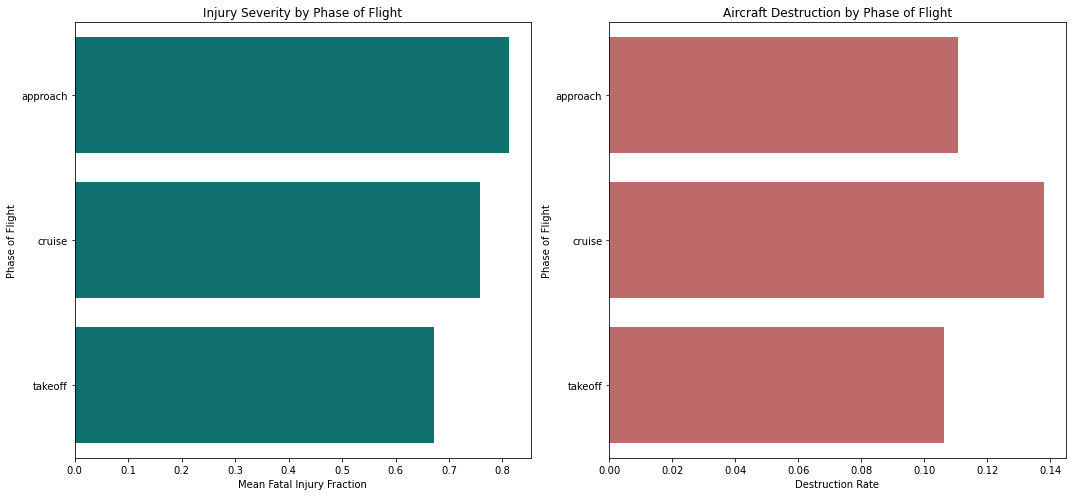

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

sns.barplot(
    data=phase_analysis,
    x="Mean_Injury_Fraction",
    y="Broad.phase.of.flight",
    color="teal",
    ax=axes[0]
)

axes[0].set_title("Injury Severity by Phase of Flight")
axes[0].set_xlabel("Mean Fatal Injury Fraction")
axes[0].set_ylabel("Phase of Flight")

sns.barplot(
    data=phase_analysis,
    x="Destruction_Rate",
    y="Broad.phase.of.flight",
    color="indianred",
    ax=axes[1]
)

axes[1].set_title("Aircraft Destruction by Phase of Flight")
axes[1].set_xlabel("Destruction Rate")
axes[1].set_ylabel("Phase of Flight")

plt.tight_layout()
plt.show()

### Factor 2: Phase of Flight

The phase of flight was examined to determine whether accident severity differs between operational stages, such as takeoff, climb, cruise, approach, landing, and ground operations.

The analysis calculated the mean fatal injury fraction and aircraft destruction rate for each recorded phase of flight.

The bar charts allow comparison of the severity of accidents occurring during different stages of aircraft operation.

Differences in injury fractions may reflect variations in operating conditions, altitude, speed, and the circumstances surrounding an accident. Similarly, differences in destruction rates indicate that some phases may be associated with more extensive aircraft damage.

However, these findings represent associations within the accident dataset and do not establish causation.

The results may help airlines and insurers identify operational stages that deserve closer attention in safety management, pilot training, and risk assessment.